# 04 · Validación y comparación de modelos

**Propósito.** Validar el precio esperado que produce la etapa 6 del pipeline (`src/analisis.py`) y decidir, con
evidencia, qué modelo y qué zona de referencia usar. Responde a cuatro pedidos de la devolución de la PreEntrega 2 y
de la consigna de la PreEntrega 3:

| Pedido | Sección |
|---|---|
| Controlar el leakage indirecto (atípicos y elección de sub-zonas con todos los avisos, particiones no agrupadas) | 2 |
| Revisar la estabilidad de las sub-zonas | 3 |
| Comparar con una referencia razonable, fuera de muestra, y justificar qué aporta cada técnica frente a una más simple | 4 |
| Reportar incertidumbre, no solo un número | 5 |
| Primas por característica con su incertidumbre, y si cambian según el segmento (pregunta G2) | 6 y 7 |

**Cómo se valida.** Todos los modelos usan las mismas cinco vueltas de validación cruzada, armadas por unidad (misma
dirección y superficie), y en cada vuelta las decisiones que dependen del precio (qué barrios usan sub-zona, qué
avisos son atípicos) se toman solo con los avisos de entrenamiento (`modelo.vueltas_sin_fuga`). El error es el error
porcentual absoluto del precio por m² de cada aviso, fuera de muestra.

## 1. Configuración e ingesta

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

from src import modelo, validacion
from src.configuracion import cargar_config
from src.eda import AZUL, AZUL_OSCURO, GRIS, ROJO, nombre_barrio

CFG = cargar_config()
PARAMS = {**CFG["analisis"], "b_bootstrap": 300}
df = pd.read_csv(RAIZ / CFG["rutas"]["limpio"], sep="\t", low_memory=False)
oficial = pd.read_csv(RAIZ / CFG["rutas"]["precio_esperado"], sep="\t")
y = np.log(df["precio_m2_usd"])
unidad = modelo.grupo_de_unidad(df)
print(f"Avisos: {len(df):,} | unidades: {unidad.nunique():,}")
PARAMS

Avisos: 27,578 | unidades: 24,552


{'k_folds': 5,
 'semilla': 42,
 'minimo_grupo': 10,
 'iqr_k': 1.5,
 'umbral': -0.25,
 'minimo_avisos_barrio': 50,
 'b_bootstrap': 300}

## 2. Leakage indirecto: ¿cuánto cambia el modelo al tomar todas las decisiones dentro de cada vuelta?

**Pregunta:** en la PreEntrega 2, la marca de atípicos y la elección de los barrios con sub-zona se calcularon con
todos los avisos antes de la validación cruzada, y la comparación de H2 usaba particiones que no agrupaban por unidad.
¿Inflaba eso el desempeño del modelo?

Se comparan cuatro versiones del mismo modelo lineal, cambiando una cosa por vez:

1. **PreEntrega 2:** decisiones con todos los avisos; atípicos con IQR sobre el precio por m².
2. **Sin fuga, mismo criterio de atípicos:** decisiones dentro de cada vuelta, partes por unidad.
3. **Sin fuga, atípicos sobre el logaritmo:** además, los atípicos se miden sobre el log del precio por m², dentro de
   la zona (es la versión oficial de la etapa 6).

In [2]:
X = modelo.matriz_caracteristicas(df)
folds = modelo.folds_agrupados(unidad, PARAMS["k_folds"], PARAMS["semilla"])

# 1. Método de la PreEntrega 2
tabla_pe2 = modelo.barrios_donde_conviene_subzona(df, PARAMS["k_folds"], PARAMS["minimo_grupo"], PARAMS["semilla"])
zona_pe2 = modelo.zona_de_referencia(df, tabla_pe2.index[tabla_pe2["conviene_subzona"]], PARAMS["minimo_grupo"])
log_pe2, _ = modelo.precio_esperado_fuera_de_muestra(y, modelo.matriz_diseno(X, zona_pe2), zona_pe2, folds,
                                                     ~df["outlier_precio_m2"])
# 2 y 3. Sin fuga
sin_fuga_lineal = modelo.precio_esperado_sin_fuga(df, y, X, atipicos_en_log=False)
sin_fuga_log = modelo.precio_esperado_sin_fuga(df, y, X, atipicos_en_log=True)

versiones = {
    "1. PreEntrega 2": log_pe2,
    "2. Sin fuga, atípicos sobre el precio": sin_fuga_lineal["log_esperado"],
    "3. Sin fuga, atípicos sobre el log (oficial)": sin_fuga_log["log_esperado"],
}
fuga = pd.DataFrame({
    nombre: {
        "error_mediano_%": 100 * (np.exp(y - pred) - 1).abs().median(),
        "error_p75_%": 100 * (np.exp(y - pred) - 1).abs().quantile(0.75),
        "marcados (brecha < −25%)": int(((np.exp(y - pred) - 1) < PARAMS["umbral"]).sum()),
    } for nombre, pred in versiones.items()
}).T.round(2)
tabla_unidad = modelo.barrios_donde_conviene_subzona(df, PARAMS["k_folds"], PARAMS["minimo_grupo"], PARAMS["semilla"],
                                                     por_unidad=True)
print(f"Barrios donde conviene la sub-zona: {tabla_pe2['conviene_subzona'].sum()} con partes al azar, "
      f"{tabla_unidad['conviene_subzona'].sum()} con partes por unidad (de {len(tabla_unidad)})")
fuga

Barrios donde conviene la sub-zona: 28 con partes al azar, 24 con partes por unidad (de 47)


,error_mediano_%,error_p75_%,marcados (brecha < −25%)
1. PreEntrega 2,12.71,22.33,1697.0
"2. Sin fuga, atípicos sobre el precio",12.72,22.33,1698.0
"3. Sin fuga, atípicos sobre el log (oficial)",12.75,22.22,1887.0


In [3]:
marca = {n: (np.exp(y - p) - 1) < PARAMS["umbral"] for n, p in versiones.items()}
nombres = list(versiones)
print("Coincidencia de los avisos marcados (Jaccard):")
for a, b in [(0, 1), (1, 2), (0, 2)]:
    print(f"  {nombres[a][:2]} vs {nombres[b][:2]}: {validacion.jaccard(marca[nombres[a]], marca[nombres[b]]):.2f}")

Coincidencia de los avisos marcados (Jaccard):
  1. vs 2.: 0.91
  2. vs 3.: 0.87
  1. vs 3.: 0.84


> **Interpretación:** _(a completar)_

## 3. Estabilidad de las sub-zonas

**Pregunta:** las sub-zonas salen de un k-means sobre latitud y longitud dentro de cada barrio. ¿Son una partición
estable del barrio o cambian con la muestra?

**Cómo se mide.** Para cada barrio se repite el k-means 50 veces, con la misma cantidad de sub-zonas, sobre
submuestras del 80% de los avisos y otra semilla; se asignan todos los avisos y se compara con las sub-zonas
originales con el **índice de Rand ajustado** (ARI: 1 = misma partición, 0 = coincidencia al azar). Se toma como
estable un ARI mediano de al menos 0,7. Solo usa coordenadas, no precios: no tiene riesgo de fuga.

In [4]:
estab = validacion.estabilidad_subzonas(df, repeticiones=50)
usa_sub = oficial.assign(usa=oficial["zona"] != oficial["barrio"]).groupby("barrio")["usa"].mean()
estab["avisos_con_subzona_%"] = (100 * usa_sub.reindex(estab.index)).round(0)
estab["estable"] = estab["ari_mediano"] >= 0.7
print(f"Barrios evaluados: {len(estab)} | estables: {estab['estable'].sum()} | inestables: {(~estab['estable']).sum()}")
estab.round(2).head(10)

Barrios evaluados: 41 | estables: 36 | inestables: 5


,avisos,subzonas,ari_mediano,ari_p10,avisos_con_subzona_%,estable
barrio,,,,,,
velez-sarsfield,64,2,-0.00,-0.00,41.0,False
parque-patricios,165,5,0.46,0.45,0.0,False
villa-santa-rita,87,3,0.46,0.34,44.0,False
coghlan,148,5,0.67,0.52,50.0,False
san-nicolas,689,5,0.69,0.50,18.0,False
villa-luro,309,5,0.74,0.46,45.0,True
san-telmo,539,5,0.74,0.67,88.0,True
recoleta,1662,5,0.75,0.52,83.0,True
almagro,1339,5,0.76,0.73,0.0,True


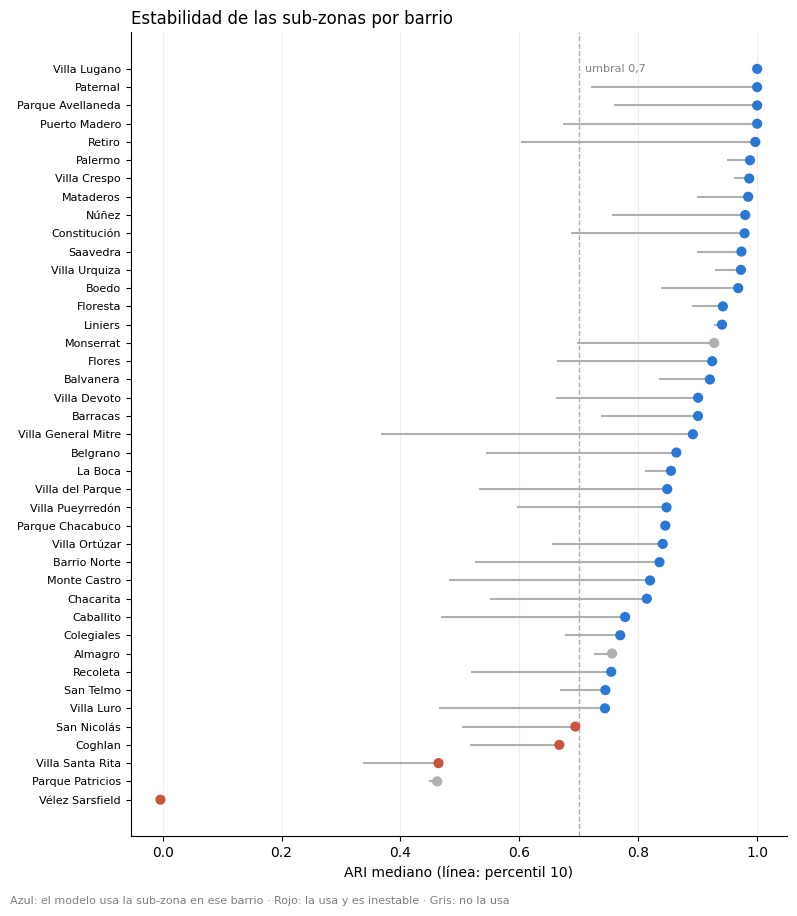

In [5]:
fig, ax = plt.subplots(figsize=(8, 9))
orden = estab.sort_values("ari_mediano")
colores = [ROJO if (not e and u > 0) else (AZUL if u > 0 else GRIS)
           for e, u in zip(orden["estable"], orden["avisos_con_subzona_%"].fillna(0))]
ax.hlines(range(len(orden)), orden["ari_p10"], orden["ari_mediano"], color=GRIS, lw=1.5)
ax.scatter(orden["ari_mediano"], range(len(orden)), color=colores, s=40, zorder=3)
ax.axvline(0.7, color=GRIS, ls="--", lw=1)
ax.set_yticks(range(len(orden)), [nombre_barrio(b) for b in orden.index], fontsize=8)
ax.set_xlabel("ARI mediano (línea: percentil 10)")
ax.set_title("Estabilidad de las sub-zonas por barrio", loc="left")
ax.text(0.71, len(orden) - 1, "umbral 0,7", color="gray", fontsize=8, va="center")
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
ax.grid(axis="x", color="#eeeeee")
plt.figtext(0.01, -0.01, "Azul: el modelo usa la sub-zona en ese barrio · Rojo: la usa y es inestable · Gris: no la usa",
            fontsize=8, color="gray")
plt.tight_layout()
plt.show()

In [6]:
inestables_en_uso = estab[~estab["estable"] & (estab["avisos_con_subzona_%"] > 0)]
print("Barrios inestables donde hoy se usa la sub-zona:")
inestables_en_uso.round(2)

Barrios inestables donde hoy se usa la sub-zona:


,avisos,subzonas,ari_mediano,ari_p10,avisos_con_subzona_%,estable
barrio,,,,,,
velez-sarsfield,64,2,-0.00,-0.00,41.0,False
villa-santa-rita,87,3,0.46,0.34,44.0,False
coghlan,148,5,0.67,0.52,50.0,False
san-nicolas,689,5,0.69,0.50,18.0,False


In [7]:
# ¿Qué pasa si esos barrios vuelven a compararse contra el barrio completo?
sin_inestables = modelo.precio_esperado_sin_fuga(df, y, X, barrios_excluidos=list(estab.index[~estab["estable"]]))
for nombre, s in [("Oficial", sin_fuga_log), ("Sin sub-zona en barrios inestables", sin_inestables)]:
    b = np.exp(y - s["log_esperado"]) - 1
    print(f"{nombre}: error mediano {100 * b.abs().median():.2f}% | marcados {(b < PARAMS['umbral']).sum():,}")

Oficial: error mediano 12.75% | marcados 1,887
Sin sub-zona en barrios inestables: error mediano 12.75% | marcados 1,886


> **Interpretación:** _(a completar)_

## 4. Comparación de modelos

**Pregunta:** ¿qué aporta cada técnica frente a una más simple?

| Modelo | Qué es | Qué aporta / qué cuesta |
|---|---|---|
| Mediana de la zona | El precio por m² típico de la zona | La referencia más simple: no usa las características del departamento |
| Lineal (PreEntrega 2) | Regresión del log del precio por m² sobre características + zona | Primas interpretables (% por característica) |
| Lineal ampliado | Más las marcas del título (estado, tipología) y las expensas relativas a la zona | Suma información que la ficha no tiene, sigue siendo interpretable |
| Ridge | El ampliado con regularización L2 | Controla el sobreajuste si hay muchas zonas con pocos avisos |
| Gradient boosting | Árboles con las mismas variables más latitud, longitud y barrio | Capta interacciones y la micro-ubicación; no da primas, es una caja más negra |

Todos con las mismas vueltas y las mismas decisiones sin fuga.

In [8]:
pred, vuelta = validacion.comparar_modelos(df, y, PARAMS["k_folds"], PARAMS["semilla"], PARAMS["minimo_grupo"],
                                           PARAMS["iqr_k"])
tabla_modelos = validacion.metricas(y, pred, PARAMS["umbral"]).round(2)
tabla_modelos

,error_mediano_%,error_p75_%,dentro_de_10%_%,marcados
mediana_zona,17.43,29.83,29.64,3398.0
lineal,12.75,22.22,40.60,1887.0
lineal_ampliado,12.58,21.87,41.06,1808.0
ridge,12.58,21.90,41.04,1803.0
gbm,11.19,19.86,45.50,1442.0


In [9]:
# IC 95% de la diferencia de error mediano contra el lineal, remuestreando unidades
dif = pd.DataFrame({m: validacion.bootstrap_diferencia_error(y, pred[m], pred["lineal"], unidad, b=PARAMS["b_bootstrap"])
                    for m in ["mediana_zona", "lineal_ampliado", "ridge", "gbm"]},
                   index=["diferencia_pp", "ic_inf_pp", "ic_sup_pp"]).T.round(2)
dif

,diferencia_pp,ic_inf_pp,ic_sup_pp
mediana_zona,4.68,4.41,4.94
lineal_ampliado,-0.16,-0.23,-0.07
ridge,-0.17,-0.25,-0.09
gbm,-1.56,-1.71,-1.38


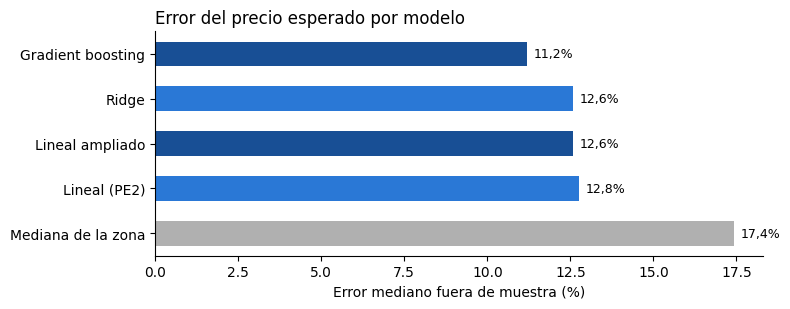

In [10]:
fig, ax = plt.subplots(figsize=(8, 3.2))
etiquetas = {"mediana_zona": "Mediana de la zona", "lineal": "Lineal (PE2)", "lineal_ampliado": "Lineal ampliado",
             "ridge": "Ridge", "gbm": "Gradient boosting"}
orden = tabla_modelos["error_mediano_%"].sort_values(ascending=False)
colores = [GRIS if m == "mediana_zona" else (AZUL_OSCURO if m in ("lineal_ampliado", "gbm") else AZUL) for m in orden.index]
ax.barh(range(len(orden)), orden.values, color=colores, height=0.55)
for i, v in enumerate(orden.values):
    ax.text(v + 0.2, i, f"{v:.1f}%".replace(".", ","), va="center", fontsize=9)
ax.set_yticks(range(len(orden)), [etiquetas[m] for m in orden.index])
ax.set_xlabel("Error mediano fuera de muestra (%)")
ax.set_title("Error del precio esperado por modelo", loc="left")
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.show()

**¿Cambia el ranking según el modelo?** Si dos modelos con error parecido marcan avisos distintos, la marca depende
de la elección del modelo y no solo del precio del aviso. Se mide la coincidencia de los marcados (Jaccard) y cuántos
marca cada par en común.

In [11]:
brechas = np.exp(y.values[:, None] - pred.values) - 1
marcas = pd.DataFrame(brechas < PARAMS["umbral"], index=df.index, columns=pred.columns)
modelos = ["lineal", "lineal_ampliado", "ridge", "gbm"]
coincidencia = pd.DataFrame([[validacion.jaccard(marcas[a], marcas[b]) for b in modelos] for a in modelos],
                            index=modelos, columns=modelos).round(2)
coincidencia

,lineal,lineal_ampliado,ridge,gbm
lineal,1.00,0.84,0.84,0.50
lineal_ampliado,0.84,1.00,0.98,0.53
ridge,0.84,0.98,1.00,0.53
gbm,0.50,0.53,0.53,1.00


In [12]:
consenso = marcas["lineal_ampliado"] & marcas["gbm"]
print(f"Marcados por el lineal ampliado: {marcas['lineal_ampliado'].sum():,} | por gradient boosting: {marcas['gbm'].sum():,} "
      f"| por los dos: {consenso.sum():,}")
# ¿Dónde se separan? Error de cada modelo por grupo de barrios según su precio
nivel = pd.qcut(df.groupby("barrio")["precio_m2_usd"].transform("median"), 3, labels=["barrios baratos", "medios", "caros"])
err = (np.exp(y.values[:, None] - pred.values) - 1)
pd.DataFrame(np.abs(err), columns=pred.columns).groupby(nivel.values, observed=True).median().mul(100).round(1)

Marcados por el lineal ampliado: 1,808 | por gradient boosting: 1,442 | por los dos: 1,128


,mediana_zona,lineal,lineal_ampliado,ridge,gbm
barrios baratos,17.5,12.7,12.6,12.6,11.3
medios,17.0,12.7,12.6,12.6,11.3
caros,17.8,12.8,12.6,12.5,11.0


> **Interpretación:** _(a completar)_

## 5. Incertidumbre: intervalo de predicción por aviso

**Pregunta:** el error mediano dice cuánto se equivoca el modelo en el aviso típico. ¿Cuánto puede equivocarse para
*un* aviso, en *su* barrio?

**Cómo se calcula (conformal cruzado).** Para los avisos de cada vuelta, el intervalo sale de los cuantiles de los
residuos fuera de muestra de las **otras** vueltas, dentro de su barrio (si tiene al menos 50 avisos; si no, de toda
la ciudad). No supone normalidad. **Cómo se valida:** la cobertura, es decir, qué proporción de avisos cae realmente
dentro de su intervalo, tiene que acercarse al nivel nominal (80% o 90%), en total y en cada barrio.

In [13]:
cobertura = []
intervalos = {}
for m in ["lineal_ampliado", "gbm"]:
    residuo = y - pred[m]
    for nivel_ic in [0.80, 0.90]:
        inf, sup = validacion.intervalos_conformes(residuo, df["barrio"], vuelta, nivel_ic)
        dentro = (residuo >= inf) & (residuo <= sup)
        por_barrio = dentro.groupby(df["barrio"]).mean()
        intervalos[(m, nivel_ic)] = (inf, sup, dentro)
        cobertura.append({"modelo": m, "nivel_%": int(100 * nivel_ic), "cobertura_%": 100 * dentro.mean(),
                          "cobertura_barrio_p10_%": 100 * por_barrio.quantile(0.1),
                          "cobertura_barrio_min_%": 100 * por_barrio.min(),
                          "ancho_mediano_%": 100 * (np.exp(sup - inf) - 1).median(),
                          "debajo_del_intervalo": int((residuo < inf).sum())})
pd.DataFrame(cobertura).round(1)

,modelo,nivel_%,cobertura_%,cobertura_barrio_p10_%,cobertura_barrio_min_%,ancho_mediano_%,debajo_del_intervalo
0,lineal_ampliado,80,79.4,75.4,43.9,64.0,2823
1,lineal_ampliado,90,89.6,86.6,53.7,93.4,1438
2,gbm,80,79.6,74.4,48.8,56.7,2801
3,gbm,90,89.5,86.8,61.0,80.7,1437


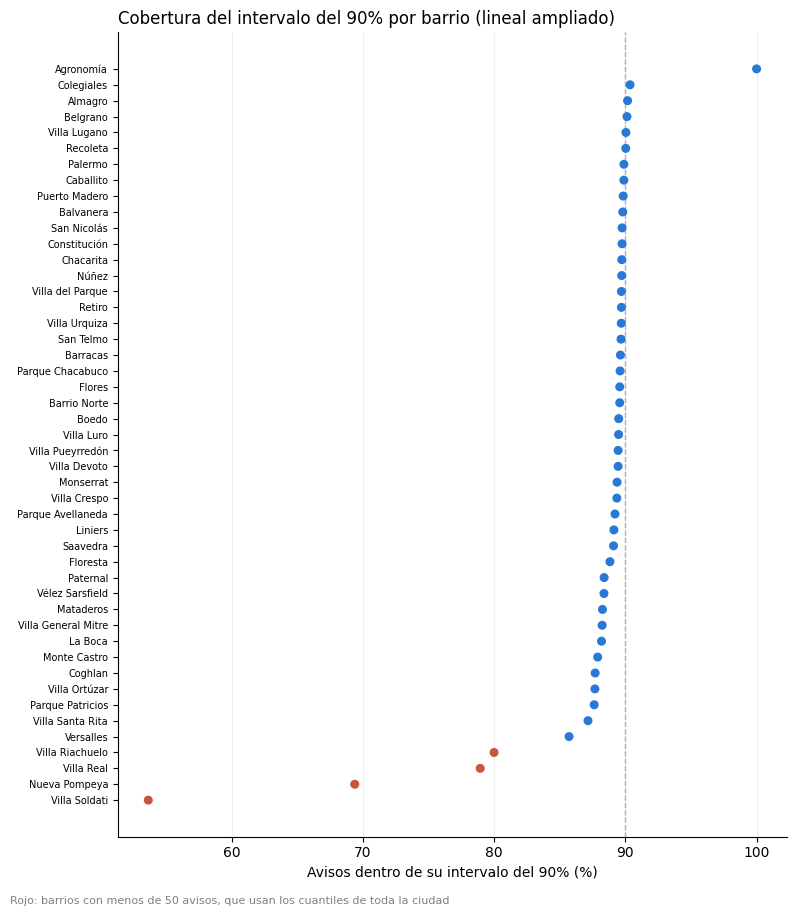

In [14]:
inf, sup, dentro = intervalos[("lineal_ampliado", 0.90)]
cob = dentro.groupby(df["barrio"]).agg(["mean", "size"]).sort_values("mean")
fig, ax = plt.subplots(figsize=(8, 9))
colores = [ROJO if n < 50 else AZUL for n in cob["size"]]
ax.scatter(100 * cob["mean"], range(len(cob)), color=colores, s=30, zorder=3)
ax.axvline(90, color=GRIS, ls="--", lw=1)
ax.set_yticks(range(len(cob)), [nombre_barrio(b) for b in cob.index], fontsize=7)
ax.set_xlabel("Avisos dentro de su intervalo del 90% (%)")
ax.set_title("Cobertura del intervalo del 90% por barrio (lineal ampliado)", loc="left")
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
ax.grid(axis="x", color="#eeeeee")
plt.figtext(0.01, -0.01, "Rojo: barrios con menos de 50 avisos, que usan los cuantiles de toda la ciudad", fontsize=8, color="gray")
plt.tight_layout()
plt.show()

In [15]:
# Lo que significa para el ranking: un aviso por debajo de su intervalo del 90% pide menos que el 95% de los avisos
# comparables de su barrio, según el error del modelo ahí. ¿Coincide con la marca por barrio de la etapa 6?
residuo = y - pred["lineal_ampliado"]
debajo = residuo < inf
print(f"Debajo del intervalo del 90%: {debajo.sum():,} avisos | marca por barrio oficial: {oficial['marcado_barrio'].sum():,} "
      f"| coincidencia (Jaccard): {validacion.jaccard(debajo, oficial['marcado_barrio']):.2f}")

Debajo del intervalo del 90%: 1,438 avisos | marca por barrio oficial: 1,631 | coincidencia (Jaccard): 0.74


> **Interpretación:** _(a completar)_

## 6. Primas por característica con su incertidumbre

**Pregunta:** ¿cuánto paga el mercado por cada característica, dentro de la misma zona, y con qué precisión lo sabemos?

El modelo lineal ampliado se ajusta con todos los avisos (sin atípicos), con la zona de referencia de la etapa 6. El
intervalo de confianza del 95% sale de remuestrear **unidades** (no avisos), porque los avisos de una misma unidad no
son independientes. Las primas son asociaciones dentro de la zona, no efectos causales.

In [16]:
from src.limpieza import outliers_iqr_por_grupo

zona = oficial["zona"]
Xa = validacion.caracteristicas_ampliadas(df)
log_exp = np.log(df["expensas_usd"] / df["m2_final"])
Xa = Xa.assign(expensas_rel_zona=(log_exp - log_exp.groupby(zona).transform("median")).fillna(0),
               expensas_sin_dato=log_exp.isna().astype(float))
A = modelo.matriz_diseno(Xa, zona)
usar = ~outliers_iqr_por_grupo(y, zona, k=PARAMS["iqr_k"], minimo_grupo=PARAMS["minimo_grupo"])
caracteristicas = [c for c in Xa.columns if c not in ("log_m2",)]
primas = validacion.bootstrap_primas(y, A, usar, unidad, caracteristicas, b=PARAMS["b_bootstrap"]).round(1)
primas["significativa"] = (primas["ic_inf_%"] > 0) | (primas["ic_sup_%"] < 0)
primas.sort_values("prima_%")

,prima_%,ic_inf_%,ic_sup_%,significativa
titulo_a_reciclar,-18.0,-20.8,-15.2,True
titulo_a_refaccionar,-15.9,-18.5,-13.3,True
titulo_casa,-13.1,-23.1,0.4,False
apto_profesional,-3.0,-3.6,-2.5,True
apto_credito,-1.5,-1.9,-1.0,True
ascensor,-0.9,-1.4,-0.3,True
contrafrente,-0.4,-1.0,0.3,False
seguridad,0.5,-0.1,1.2,False
piso,0.7,0.6,0.8,True
antiguedad_51_70,0.7,-1.0,2.2,False


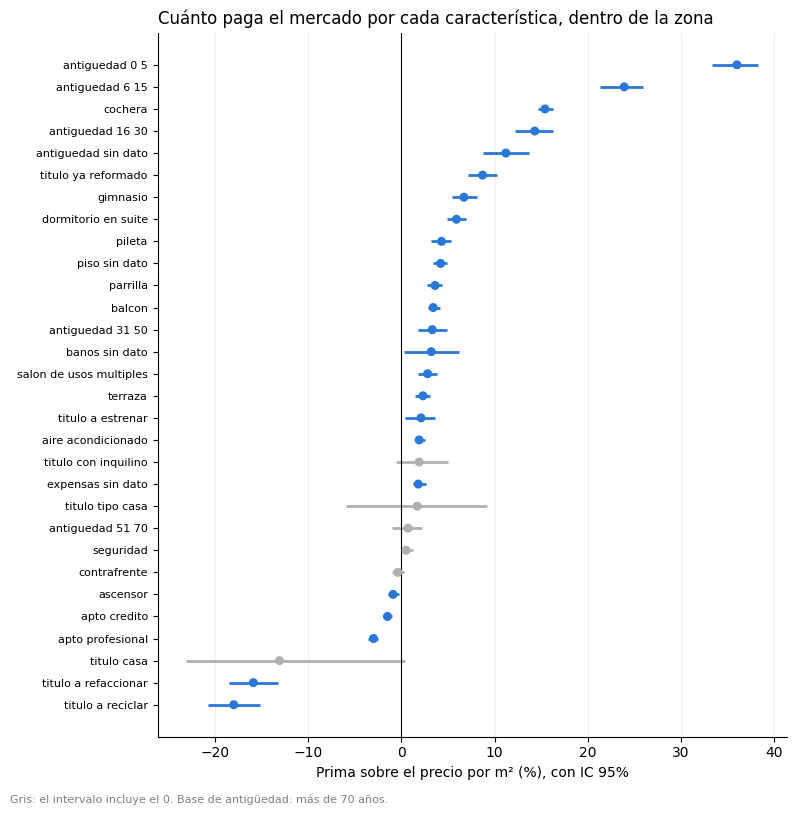

In [17]:
mostrar = primas.drop(["piso", "ambientes", "banos", "expensas_rel_zona"]).sort_values("prima_%")
fig, ax = plt.subplots(figsize=(8, 8))
color = [AZUL if s else GRIS for s in mostrar["significativa"]]
ax.hlines(range(len(mostrar)), mostrar["ic_inf_%"], mostrar["ic_sup_%"], color=color, lw=2)
ax.scatter(mostrar["prima_%"], range(len(mostrar)), color=color, s=30, zorder=3)
ax.axvline(0, color="black", lw=0.8)
ax.set_yticks(range(len(mostrar)), [c.replace("_", " ") for c in mostrar.index], fontsize=8)
ax.set_xlabel("Prima sobre el precio por m² (%), con IC 95%")
ax.set_title("Cuánto paga el mercado por cada característica, dentro de la zona", loc="left")
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
ax.grid(axis="x", color="#eeeeee")
plt.figtext(0.01, -0.01, "Gris: el intervalo incluye el 0. Base de antigüedad: más de 70 años.", fontsize=8, color="gray")
plt.tight_layout()
plt.show()

In [18]:
coef = modelo.ajustar(y, A, usar)
print(f"Superficie: +10% de m² se asocia a {modelo.prima_porcentual(coef['log_m2'] * np.log(1.1)):.1f}% de precio por m²")
print(f"Expensas: un edificio con expensas por m² 10% más caras que la mediana de su zona se publica "
      f"{modelo.prima_porcentual(coef['expensas_rel_zona'] * np.log(1.1)):+.1f}% por m²")
for c in ["ambientes", "banos", "piso"]:
    print(f"{c}: {primas.loc[c, 'prima_%']:+.1f}% por unidad adicional (IC {primas.loc[c, 'ic_inf_%']:+.1f} a {primas.loc[c, 'ic_sup_%']:+.1f})")

Superficie: +10% de m² se asocia a -1.6% de precio por m²
Expensas: un edificio con expensas por m² 10% más caras que la mediana de su zona se publica +0.3% por m²
ambientes: +2.2% por unidad adicional (IC +1.6 a +2.6)
banos: +4.7% por unidad adicional (IC +4.1 a +5.4)
piso: +0.7% por unidad adicional (IC +0.6 a +0.8)


> **Interpretación:** _(a completar)_

## 7. ¿Las primas cambian según el segmento? (pregunta G2)

**Pregunta:** un solo coeficiente por característica para toda la ciudad, ¿alcanza? Se separan los barrios en tres
grupos según su precio mediano por m² (baratos, medios, caros) y se estima el mismo modelo en cada grupo. Si los
intervalos de una característica no se superponen entre grupos, su prima depende del segmento.

In [19]:
segmento = pd.qcut(df.groupby("barrio")["precio_m2_usd"].transform("median"), 3, labels=["baratos", "medios", "caros"])
clave = ["antiguedad_0_5", "antiguedad_6_15", "cochera", "pileta", "seguridad", "balcon", "contrafrente",
         "titulo_a_refaccionar", "titulo_a_reciclar"]
por_segmento = {}
for seg in ["baratos", "medios", "caros"]:
    en = (segmento == seg).values
    A_seg = modelo.matriz_diseno(Xa[en], zona[en])
    por_segmento[seg] = validacion.bootstrap_primas(y[en], A_seg, usar[en], unidad[en], clave, b=150)
g2 = pd.concat(por_segmento, names=["segmento", "caracteristica"]).round(1)
g2.unstack(0)["prima_%"]

segmento,baratos,medios,caros
caracteristica,,,
antiguedad_0_5,34.8,31.4,31.0
antiguedad_6_15,25.2,22.4,16.9
cochera,15.6,15.4,13.8
pileta,6.3,5.1,3.5
seguridad,-0.2,-1.2,2.6
balcon,5.3,2.2,2.5
contrafrente,-0.9,-0.2,0.0
titulo_a_refaccionar,-15.3,-18.1,-15.8
titulo_a_reciclar,-16.2,-18.5,-17.6


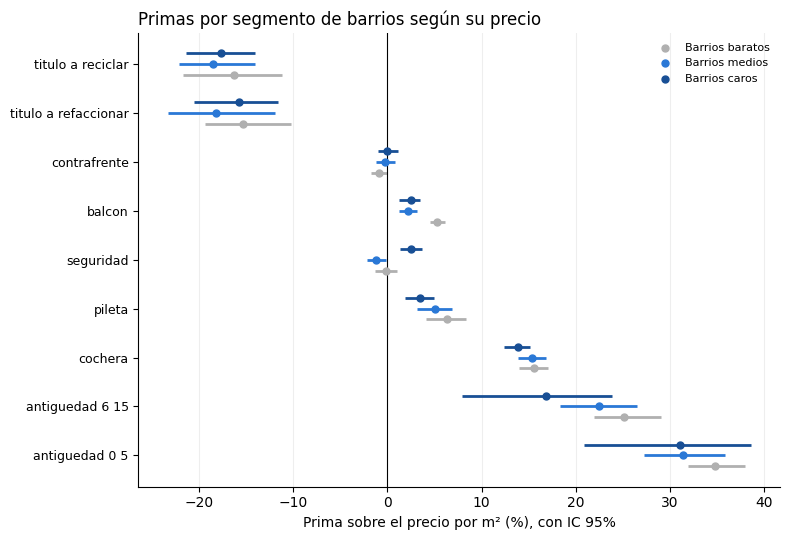

In [20]:
fig, ax = plt.subplots(figsize=(8, 5.5))
colores_seg = {"baratos": GRIS, "medios": AZUL, "caros": AZUL_OSCURO}
desplazamiento = {"baratos": -0.22, "medios": 0, "caros": 0.22}
for seg, tabla in por_segmento.items():
    ys = np.arange(len(clave)) + desplazamiento[seg]
    ax.hlines(ys, tabla["ic_inf_%"], tabla["ic_sup_%"], color=colores_seg[seg], lw=2)
    ax.scatter(tabla["prima_%"], ys, color=colores_seg[seg], s=25, zorder=3, label=f"Barrios {seg}")
ax.axvline(0, color="black", lw=0.8)
ax.set_yticks(range(len(clave)), [c.replace("_", " ") for c in clave], fontsize=9)
ax.set_xlabel("Prima sobre el precio por m² (%), con IC 95%")
ax.set_title("Primas por segmento de barrios según su precio", loc="left")
ax.legend(frameon=False, fontsize=8, loc="upper right")
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
ax.grid(axis="x", color="#eeeeee")
plt.tight_layout()
plt.show()

> **Interpretación:** _(a completar)_

## 8. Conclusiones y decisiones para la etapa 6

_(a completar con las decisiones que tomemos a partir de las secciones 2 a 7: modelo oficial, uso de las sub-zonas
inestables, intervalo de predicción en el ranking y en el dashboard, y qué se le dice al analista sobre la
incertidumbre de cada brecha.)_